# Lunar Lander — REINFORCE with Baseline

This notebook trains an agent to land a spacecraft using **REINFORCE with a learned baseline** — a small step up from vanilla policy gradient that dramatically reduces training variance. Lunar Lander is a great demo because:

- The task is visually intuitive and satisfying to watch
- The reward function is carefully shaped (partial rewards for hovering, orientation, velocity, leg contact; penalties for crashing and fuel use) — good for discussing reward design
- It's hard enough that the improvement over training is dramatic and visible
- It bridges naturally to actor-critic methods: the baseline network here is essentially a critic

**The environment (LunarLander-v3):**
- **State:** 8 numbers — x/y position, x/y velocity, angle, angular velocity, left/right leg contact
- **Actions:** 4 discrete — do nothing, fire left thruster, fire main engine, fire right thruster
- **Reward:** +100–140 for landing, −100 for crashing, small shaping rewards at each step
- **Solved:** average score ≥ 200 over 100 consecutive episodes

**Visualization:** Every few episodes we render the lander to an inline video. The progression from crashing immediately to controlled landing is very satisfying.

Set your Colab runtime to GPU for a modest speedup (the network is small but the episodes are long).


In [ ]:
import subprocess
import sys
import platform

# swig must come first — gymnasium[box2d] builds Box2D from source and needs it
subprocess.run([sys.executable, '-m', 'pip', 'install', 'swig', '-q'], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install',
                'gymnasium[box2d]', 'moviepy', '-q'], check=True)

# Virtual display only needed on Linux (Colab)
if platform.system() == 'Linux':
    subprocess.run(['apt-get', 'install', '-y', 'xvfb', '-q'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install',
                    'pyvirtualdisplay', '-q'], check=True)
    from pyvirtualdisplay import Display
    display = Display(visible=0, size=(600, 400))
    display.start()
    print("Virtual display started (Linux/Colab mode).")
else:
    print(f"Running on {platform.system()} — no virtual display needed.")

Virtual display started (Linux/Colab mode).


In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical
import gymnasium as gym
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display as ipy_display
from collections import deque

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# --- Hyperparameters ---
GAMMA          = 0.99
LR_POLICY      = 3e-4
LR_BASELINE    = 1e-3
HIDDEN         = 256
MAX_EPISODES   = 2000
SOLVED_SCORE   = 200       # Official LunarLander solved threshold
RENDER_EVERY   = 200       # Render a video every N episodes
MAX_STEPS      = 1000      # Max steps per episode

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {DEVICE}")


Device: cuda


## 1. Policy and Baseline Networks

We use two networks this time:

- **Policy network** — maps the 8-dimensional state to a probability distribution over 4 actions (same idea as CartPole, just bigger)
- **Baseline network** — maps the state to a single scalar estimating the expected return from that state: $V(s)$

The baseline doesn't affect what the agent does — it's only used during training to reduce the variance of the gradient estimate. Instead of weighting each action's log probability by the raw return $G_t$, we weight it by the **advantage** $A_t = G_t - V(s_t)$: how much better did this action do than we expected? This is the key idea behind actor-critic methods; here we're doing it in a simple, episodic way.


In [ ]:
class PolicyNet(nn.Module):
    def __init__(self, state_dim, action_dim, hidden=HIDDEN):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden),    nn.ReLU(),
            nn.Linear(hidden, action_dim)
        )

    def forward(self, x):
        return torch.softmax(self.net(x), dim=-1)

    def act(self, state):
        state  = torch.tensor(state, dtype=torch.float32).to(DEVICE)
        probs  = self(state)
        dist   = Categorical(probs)
        action = dist.sample()
        return action.item(), dist.log_prob(action), dist.entropy()

class BaselineNet(nn.Module):
    """
    Estimates V(s): expected return from state s.
    This is a critic in actor-critic terminology.
    """
    def __init__(self, state_dim, hidden=HIDDEN):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden),    nn.ReLU(),
            nn.Linear(hidden, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

env        = gym.make('LunarLander-v3')
state_dim  = env.observation_space.shape[0]   # 8
action_dim = env.action_space.n               # 4

policy   = PolicyNet(state_dim, action_dim).to(DEVICE)
baseline = BaselineNet(state_dim).to(DEVICE)
opt_p    = torch.optim.Adam(policy.parameters(),   lr=LR_POLICY)
opt_b    = torch.optim.Adam(baseline.parameters(), lr=LR_BASELINE)

print(f"Policy:   {sum(p.numel() for p in policy.parameters()):,} parameters")
print(f"Baseline: {sum(p.numel() for p in baseline.parameters()):,} parameters")
print(f"State dim: {state_dim}  |  Actions: {action_dim}")
print(f"Actions: 0=nothing  1=left thruster  2=main engine  3=right thruster")


Policy:   69,124 parameters
Baseline: 68,353 parameters
State dim: 8  |  Actions: 4
Actions: 0=nothing  1=left thruster  2=main engine  3=right thruster


## 2. Training Logic

Three functions:
1. `run_episode` — collect one full episode of (state, action, log_prob, entropy, reward) tuples
2. `compute_returns` — discount the rewards into returns $G_t$
3. `update` — compute the advantage, update the policy using the advantage-weighted gradient, and update the baseline to better predict returns

The entropy bonus in the policy loss encourages exploration — without it the policy tends to collapse onto a single action early in training before it has found anything useful. We decay the entropy coefficient over time so exploration is encouraged early but the policy is allowed to commit later.


In [ ]:
def compute_returns(rewards, gamma=GAMMA):
    returns, R = [], 0.0
    for r in reversed(rewards):
        R = r + gamma * R
        returns.insert(0, R)
    return torch.tensor(returns, dtype=torch.float32).to(DEVICE)

def run_episode(env):
    state, _    = env.reset(seed=SEED)
    log_probs, entropies, rewards, states = [], [], [], []
    for _ in range(MAX_STEPS):
        action, log_prob, entropy = policy.act(state)
        states.append(state)
        log_probs.append(log_prob)
        entropies.append(entropy)
        state, reward, terminated, truncated, _ = env.step(action)
        rewards.append(reward)
        if terminated or truncated:
            break
    return log_probs, entropies, rewards, states

def update(log_probs, entropies, rewards, states, entropy_coef=0.01):
    returns    = compute_returns(rewards)
    states_t   = torch.tensor(np.array(states), dtype=torch.float32).to(DEVICE)

    # Baseline prediction and advantage
    with torch.no_grad():
        values    = baseline(states_t)
    advantages = returns - values
    # Normalise advantages for stability
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    # Policy loss: advantage-weighted log probs minus entropy bonus
    policy_loss = -torch.stack(
        [lp * adv for lp, adv in zip(log_probs, advantages)]
    ).sum() - entropy_coef * torch.stack(entropies).sum()

    opt_p.zero_grad()
    policy_loss.backward()
    torch.nn.utils.clip_grad_norm_(policy.parameters(), 0.5)
    opt_p.step()

    # Baseline loss: MSE against actual returns
    values_new    = baseline(states_t)
    baseline_loss = nn.functional.mse_loss(values_new, returns)

    opt_b.zero_grad()
    baseline_loss.backward()
    opt_b.step()

    return policy_loss.item(), baseline_loss.item()


In [ ]:
def render_episode(label=''):
    """Render one episode of the current policy as an inline HTML video."""
    env_r    = gym.make('LunarLander-v3', render_mode='rgb_array')
    state, _ = env_r.reset(seed=SEED)
    frames, total_r = [], 0
    for _ in range(MAX_STEPS):
        frames.append(env_r.render())
        action, _, _ = policy.act(state)
        state, reward, terminated, truncated, _ = env_r.step(action)
        total_r += reward
        if terminated or truncated:
            break
    env_r.close()

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.axis('off')
    ax.set_title(f'{label}  |  score: {total_r:.1f}', fontsize=11)
    im = ax.imshow(frames[0])

    def upd(i):
        im.set_data(frames[i])
        return [im]

    ani = animation.FuncAnimation(fig, upd, frames=len(frames), interval=30, blit=True)
    plt.close(fig)
    return HTML(ani.to_jshtml()), total_r


## 3. Training

This takes longer than CartPole — expect 20–30 minutes on Colab GPU to reach 200+. The score will be negative for a long time (the lander is crashing or flying off screen), then start climbing as it learns to hover, then improve further as it learns to actually land. Watch the videos every 200 episodes to see this progression.

The entropy coefficient starts at 0.01 and decays slowly — if you see the agent get stuck in a loop early (just firing thrusters randomly), try increasing it to 0.05.


In [ ]:
env              = gym.make('LunarLander-v3')
episode_scores   = []
recent           = deque(maxlen=100)
videos           = {}
entropy_coef     = 0.01

print(f"Training REINFORCE+baseline on LunarLander-v3 for up to {MAX_EPISODES} episodes...\n")
print(f"Rendering every {RENDER_EVERY} episodes. Expect ~20-30 min on GPU.\n")

for ep in range(1, MAX_EPISODES + 1):
    # Decay entropy bonus — encourage exploration early, let it commit later
    entropy_coef = max(0.001, entropy_coef * 0.9995)

    log_probs, entropies, rewards, states = run_episode(env)
    p_loss, b_loss = update(log_probs, entropies, rewards, states, entropy_coef)

    score = sum(rewards)
    episode_scores.append(score)
    recent.append(score)
    avg = np.mean(recent)

    if ep % 100 == 0:
        print(f"Ep {ep:4d} | score {score:8.1f} | avg100 {avg:7.1f} | "
              f"p_loss {p_loss:8.2f} | b_loss {b_loss:7.2f} | ent_coef {entropy_coef:.4f}")

    if ep % RENDER_EVERY == 0 or ep == 1:
        vid, vid_score = render_episode(label=f'Episode {ep}')
        videos[ep]     = (vid, vid_score)
        print(f"  -> Rendered episode {ep}: score {vid_score:.1f}")

    if avg >= SOLVED_SCORE and ep >= 100:
        print(f"\nSolved at episode {ep}! avg100 = {avg:.1f}")
        vid, vid_score = render_episode(label=f'Episode {ep} — SOLVED!')
        videos[ep]     = (vid, vid_score)
        break

env.close()
print("\nTraining complete.")


Training REINFORCE+baseline on LunarLander-v3 for up to 2000 episodes...

Rendering every 200 episodes. Expect ~20-30 min on GPU.

  -> Rendered episode 1: score -256.6
Ep  100 | score   -220.1 | avg100  -148.5 | p_loss    -2.03 | b_loss 1169.27 | ent_coef 0.0095
Ep  200 | score    -89.6 | avg100  -123.5 | p_loss     0.61 | b_loss  321.06 | ent_coef 0.0090
  -> Rendered episode 200: score -93.6
Ep  300 | score    -74.9 | avg100   -75.3 | p_loss    14.01 | b_loss  438.49 | ent_coef 0.0086
Ep  400 | score    -12.4 | avg100   -54.0 | p_loss     6.78 | b_loss  688.56 | ent_coef 0.0082
  -> Rendered episode 400: score -42.9
Ep  500 | score   -249.4 | avg100   -28.4 | p_loss     0.79 | b_loss 10302.56 | ent_coef 0.0078
Ep  600 | score     97.9 | avg100    12.6 | p_loss   -64.10 | b_loss  676.02 | ent_coef 0.0074
  -> Rendered episode 600: score -235.0
Ep  700 | score     86.5 | avg100    31.8 | p_loss   -12.80 | b_loss  660.32 | ent_coef 0.0070
Ep  800 | score    117.7 | avg100    52.7 | p_l

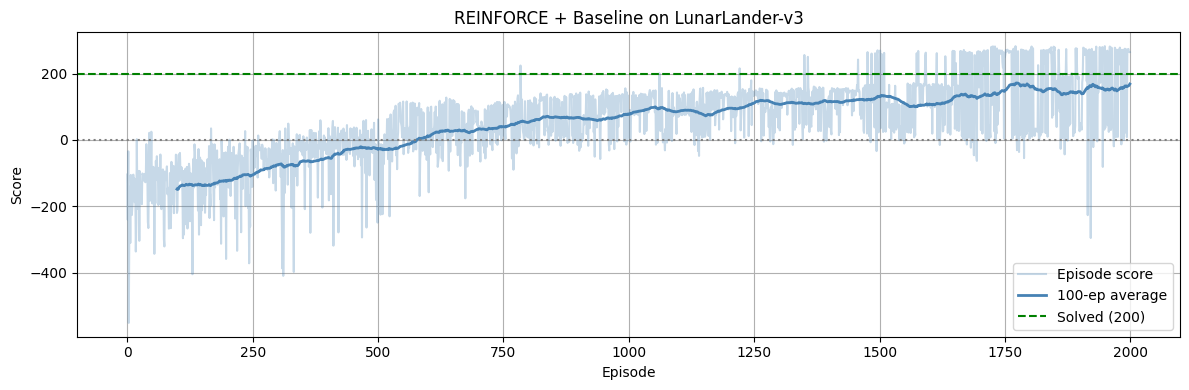

In [ ]:
# --- Score curve ---
plt.figure(figsize=(12, 4))
plt.plot(episode_scores, alpha=0.3, color='steelblue', label='Episode score')
w = 100
if len(episode_scores) >= w:
    roll = np.convolve(episode_scores, np.ones(w)/w, mode='valid')
    plt.plot(range(w-1, len(episode_scores)), roll, linewidth=2,
             color='steelblue', label=f'{w}-ep average')
plt.axhline(SOLVED_SCORE, color='green', linestyle='--', label=f'Solved ({SOLVED_SCORE})')
plt.axhline(0, color='gray', linestyle=':')
plt.xlabel('Episode')
plt.ylabel('Score')
plt.title('REINFORCE + Baseline on LunarLander-v3')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## 4. Watching the Progression


In [ ]:
for ep_num, (video, score) in sorted(videos.items()):
    print(f"=== Episode {ep_num}  |  score: {score:.1f} ===")
    ipy_display(video)


## 5. What's Going On?

**The reward shaping story**

Lunar Lander is a good example of careful reward design. The environment gives:
- A large positive reward for landing (+100 to +140 depending on precision)
- A large penalty for crashing (−100)
- Small per-step rewards for moving toward the pad, reducing velocity, staying upright
- A small penalty for firing the main engine (fuel costs something)

Without the per-step shaping rewards, the agent would almost never stumble onto a landing by chance and the training signal would be nearly pure noise for thousands of episodes. The shaping rewards are a form of domain knowledge baked into the environment.

**Why does the score go negative before it goes positive?**

Early in training the agent fires thrusters randomly and usually crashes. Each crash is −100. The per-step shaping rewards are small. So the average score is dominated by crash penalties. As the agent learns to avoid crashing (even if it just hovers uselessly), the score climbs toward zero. Only once it's consistently not crashing does it start to accumulate the positive landing rewards.

**From here to PPO**

REINFORCE with a baseline is essentially a one-step actor-critic. The main limitation is that we update the policy once per episode using high-variance Monte Carlo returns. Proximal Policy Optimisation (PPO) fixes this by:
1. Collecting a batch of experience across multiple episodes
2. Doing multiple gradient updates on the same batch (with a clipping term to prevent too-large updates)
3. Using a generalised advantage estimator (GAE) instead of raw returns

PPO would solve LunarLander in roughly a third of the episodes — but the core idea of "advantage-weighted policy gradient" is exactly what we implemented here.

**Connection to diffusion models**

In diffusion, the model learns to reverse a noisy process step by step. In RL, the agent learns to reverse a bad situation (crashed / off-target) step by step. Both are learning a sequence of decisions under uncertainty where the quality signal comes partly from the current step and partly from what happens later — which is exactly what the discount factor $\gamma$ and the return $G_t$ are encoding.


In [ ]:
# --- Inspect what the agent has learned ---
# Sample a few states from a rendered episode and show the action probabilities.
# This makes the policy interpretable: you can see it preferring the main engine
# when falling fast, and left/right thrusters to correct orientation.

env_r    = gym.make('LunarLander-v3', render_mode='rgb_array')
state, _ = env_r.reset(seed=SEED)
action_names = ['Nothing', 'Left thruster', 'Main engine', 'Right thruster']

print("Action probabilities at selected timesteps:\n")
print(f"{'Step':>5}  {'Nothing':>10}  {'Left':>10}  {'Main':>10}  {'Right':>10}  {'Chosen':>15}")
print("-" * 65)

for step in range(200):
    state_t = torch.tensor(state, dtype=torch.float32).to(DEVICE)
    with torch.no_grad():
        probs = policy(state_t).cpu().numpy()
    action = np.argmax(probs)
    if step % 20 == 0:
        print(f"{step:>5}  {probs[0]:>10.3f}  {probs[1]:>10.3f}  {probs[2]:>10.3f}  {probs[3]:>10.3f}  {action_names[action]:>15}")
    state, _, terminated, truncated, _ = env_r.step(action)
    if terminated or truncated:
        break

env_r.close()


Action probabilities at selected timesteps:

 Step     Nothing        Left        Main       Right           Chosen
-----------------------------------------------------------------
    0       0.733       0.258       0.000       0.009          Nothing
   20       0.614       0.375       0.000       0.011          Nothing
   40       0.476       0.479       0.020       0.025    Left thruster
   60       0.231       0.170       0.531       0.068      Main engine
   80       0.301       0.076       0.354       0.268      Main engine
  100       0.200       0.028       0.344       0.428   Right thruster
  120       0.180       0.030       0.460       0.330      Main engine
  140       0.275       0.057       0.404       0.264      Main engine
  160       0.328       0.206       0.394       0.073      Main engine
  180       0.294       0.345       0.328       0.033    Left thruster
